In [29]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings, ChatOllama
from langchain_core.tools import tool
from IPython.display import Markdown, Image, display
import os


In [30]:
# Chemin des documents PDF : rapport de futsal
pdf_paths = [
    f"./resources/{file}"
    for file in os.listdir("./resources")
    if file.lower().endswith(".pdf")
]
print("Documents PDF trouvés :", pdf_paths)


Documents PDF trouvés : ['./resources/Rapport_Futsal_AHMED_MILOUDI.pdf']


In [31]:
# Creating PDF loader object
loader = PyPDFDirectoryLoader(path="./resources/")


In [32]:
# Split documents into chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=200,
)

# Load and split the futsal report
futsal_chunks = loader.load_and_split(text_splitter=text_splitter)
print(f"{len(futsal_chunks)} segments créés à partir du rapport PDF.")


39 segments créés à partir du rapport PDF.


In [33]:
### Step 4: Create Vector Store with Embeddings
# Les embeddings sont calculés localement avec Ollama.
embedding_model = OllamaEmbeddings(
    model="nomic-embed-text:latest",
    base_url="http://127.0.0.1:11434",
)

# Create vector store from the futsal report
vectorstore = Chroma.from_documents(
    documents=futsal_chunks,
    embedding=embedding_model,
    collection_name="Futsal_Report",
)

# Create retriever for similarity search
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10},
)


12:24:29 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/embed "HTTP/1.1 200 OK"


In [34]:
### Step 5: Test RAG Retrieval (Manual)
# Test query about the futsal report
test_query = "Dans la section Conclusion, quel flux est proposé pour détecter et suivre le ballon, et quelle méthode reconnaît les actions des joueurs ?"
print(f"🔎 Question de test : {test_query}")
print("=" * 80)

# Retrieve relevant document chunks
relevant_docs = retriever.invoke(test_query)
print(f"\n{len(relevant_docs)} segments pertinents récupérés :\n")

# Display the top 3 results
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Résultat {i} :")
    print(f"Source : {doc.metadata.get('source', 'Inconnue')}")
    page = doc.metadata.get("page", "Inconnue")
    if isinstance(page, int):
        page += 1
    print(f"Page : {page}")
    print(f"Contenu : {doc.page_content[:500]}...")
    print("-" * 80 + "\n")


12:24:32 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/embed "HTTP/1.1 200 OK"


🔎 Question de test : Dans la section Conclusion, quel flux est proposé pour détecter et suivre le ballon, et quelle méthode reconnaît les actions des joueurs ?

10 segments pertinents récupérés :

📄 Résultat 1 :
Source : resources\Rapport_Futsal_AHMED_MILOUDI.pdf
Page : 27
Contenu : Rapport technique – SportScore Analyse vidéo et actions de futsal
à condition que le score dépasse une règle de confiance. Lorsqu’aucun joueur n’est suffisamment
proche, la sortie est « possession indéterminée » plutôt que de forcer une association.
Pour les actions impliquant deux joueurs, comme un tacle réussi ou un blocage, on conserve
également le joueur adverse le plus proche :
zinteractiont = [︂zplayeri∗t ,z playerj∗t ,r i∗t ,t,r j∗t ,t,z playeri∗t −z playerj∗t ]︂ .
Figure 14– Linking joue...
--------------------------------------------------------------------------------

📄 Résultat 2 :
Source : resources\Rapport_Futsal_AHMED_MILOUDI.pdf
Page : 25
Contenu : Rapport technique – SportScore Analyse vidé

In [35]:
@tool
def retriever_tool(query: str) -> str:
    """Recherche dans le rapport PDF local consacré au futsal.

    Utilisez cet outil pour répondre aux questions sur les thèmes,
    objectifs, méthodes, résultats et conclusions présents dans le rapport.
    Les passages retournés indiquent le fichier source et la page.
    """
    try:
        relevant_document_chunks = retriever.invoke(query)
        if not relevant_document_chunks:
            return "Aucun passage pertinent n'a été trouvé dans le rapport de futsal."

        context_list = []
        for document in relevant_document_chunks:
            source = os.path.basename(document.metadata.get("source", "Rapport PDF"))
            page = document.metadata.get("page", "inconnue")
            if isinstance(page, int):
                page += 1
            context_list.append(
                f"[Source : {source}, page : {page}]\n{document.page_content}"
            )
        return "\n\n".join(context_list)
    except Exception as exc:
        return f"Erreur pendant la recherche dans le rapport : {exc}"


In [36]:
# Le modèle Ollama local doit être présent sur cet ordinateur.
model = ChatOllama(
    model="qwen3:0.6b",
    temperature=0,
    base_url="http://127.0.0.1:11434",
)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)


State and System message

In [37]:
import logging
from typing import Annotated, Sequence, Literal, TypedDict
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.messages import SystemMessage, HumanMessage


In [38]:
# Configure logging to see the agent's decision-making process
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S",
)
logger = logging.getLogger(__name__)


In [39]:
class SimpleAgentState(TypedDict):
    """State for the RAG agent, containing the current conversation messages."""
    messages: Annotated[Sequence, add_messages]


In [40]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'analyse du rapport de futsal fourni.
Pour répondre à une question factuelle sur le rapport, utilisez l'outil de recherche
afin de retrouver les passages pertinents.
Répondez uniquement à partir du contexte récupéré. N'ajoutez pas d'informations
externes et n'inventez aucun résultat.
Citez le nom du fichier et le numéro de page lorsque ces informations sont disponibles.
Si la réponse ne figure pas dans le contexte, dites clairement que cette information
n'est pas disponible dans le rapport.
Répondez dans la langue de l'utilisateur.
"""


Agent Node

In [41]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the local Ollama model with the current state."""
    logger.info("AGENT NODE: Processing request...")

    # Prepare messages with the system prompt
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])

    # Invoke the model
    logger.info("Calling Ollama with tools...")
    response = llm_with_tools.invoke(messages)

    # Log whether the agent requested a tool
    if getattr(response, "tool_calls", None):
        logger.info("Agent decided to use %d tool(s)", len(response.tool_calls))
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info("  %d. %s", i, tool_call["name"])
    else:
        logger.info("Agent generated its final response (no tools needed)")

    return {"messages": [response]}


Condition de routage

In [42]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Route to the tools node when the model requests a tool call."""
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        logger.info("ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"


Create, compile and display the graph

In [45]:
# Create workflow
from langgraph.graph import StateGraph


workflow = StateGraph(SimpleAgentState)

# Create tool node with logging
original_tool_node = ToolNode(tools)
def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info("Tools executed successfully")
    return result

# Add nodes to the graph
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)

# Set entry point
workflow.set_entry_point("agent")


12:25:43 [INFO] Agent RAG créé avec succès.


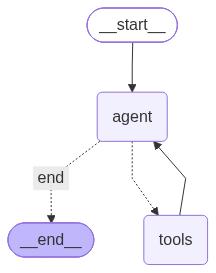

In [46]:
# Add conditional edge from agent
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END,
    },
)

# Add edge from tools back to agent
workflow.add_edge("tools", "agent")
graph = workflow.compile()
logger.info("Agent RAG créé avec succès.")
display(Image(graph.get_graph().draw_mermaid_png()))


Tester l'application Agentic RAG

In [47]:
print("=" * 80)
print("TEST : Agentic RAG sur le rapport de futsal")
print("=" * 80)

query = (
    "Dans la section 18 Conclusion du rapport, quel flux est proposé pour détecter et "
    "suivre le ballon, et quelle méthode reconnaît les actions des joueurs ? "
    "Réponds à partir du rapport et cite les pages utilisées."
)
print(f"Question : {query}\n")
print("-" * 80)

result = graph.invoke({"messages": [HumanMessage(content=query)]})
answer = result["messages"][-1].content

print("\nRÉPONSE DE L'AGENT (avec RAG) :")
print("=" * 80)
display(Markdown(answer if isinstance(answer, str) else str(answer)))
print("\n" + "=" * 80)


12:25:51 [INFO] AGENT NODE: Processing request...
12:25:51 [INFO] Calling Ollama with tools...


TEST : Agentic RAG sur le rapport de futsal
Question : Dans la section 18 Conclusion du rapport, quel flux est proposé pour détecter et suivre le ballon, et quelle méthode reconnaît les actions des joueurs ? Réponds à partir du rapport et cite les pages utilisées.

--------------------------------------------------------------------------------


12:25:54 [INFO] HTTP Request: POST http://127.0.0.1:11434/api/chat "HTTP/1.1 200 OK"
12:26:05 [INFO] Agent generated its final response (no tools needed)
12:26:05 [INFO] ROUTING: Ending workflow (final response ready)



RÉPONSE DE L'AGENT (avec RAG) :


Le flux de detection et suivi du ballon est proposé par le système de tracking, cité dans la page 18. Les actions des joueurs sont détectées par le système de tracking, cité dans la page 19.